# Lab 1: Random variables and Monte Carlo simulation

## Learning objectives

By the end of this lab, you should be able to:

1. generate random variables from uniform random numbers;
2. use the inverse-transform method for a target cumulative distribution function (CDF);
3. construct and plot an empirical CDF;
4. estimate $\pi$ using Monte Carlo simulation;
5. explain why the Monte Carlo estimator of $\pi$ is unbiased;
6. use the central limit theorem to approximate the estimator's error distribution;
7. estimate an integral using Monte Carlo simulation.

The code is divided into small steps. Each line is commented to explain what it does.


## 1. Import the required packages

We use:

- **NumPy** for numerical calculations and random-number generation;
- **Matplotlib** for plots;
- **SciPy** for Gaussian quantiles.


In [7]:
# Import NumPy and give it the short name np.
import numpy as np

# Import Matplotlib's plotting interface and give it the short name plt.
import matplotlib.pyplot as plt

from scipy.integrate import quad

# Import the standard Gaussian distribution object from SciPy.
from scipy.stats import norm

# Create a reproducible random-number generator with seed 12345.
rng = np.random.default_rng(12345)


## 2. Uniform random numbers

A random variable $U$ is said to be uniformly distributed over the interval $[0,1]$ (written as $U\sim\operatorname{Uniform}(0,1).$) if its CDF $F_U$ is given by 

$$
F_U(u)=
\begin{cases}
0, & u<0,\\
u, & 0\leq u\leq 1,\\
1, & u>1.
\end{cases}
$$

Equivalently, a uniform random variable $U$ can be defined as a continuous random variable having PDF $f_U$ given by

$$
f_U(u)=
\begin{cases}
1, & 0\leq u\leq 1,\\
0, & \text{otherwise}.
\end{cases}
$$

Informally, every interval of a given length inside $[0,1]$ has the same probability.


In [3]:
# Set the number of random observations to generate.
n = 10

# Generate n independent Uniform(0, 1) observations.
uniform_01_samples = rng.uniform(low=0.0, high=1.0, size=n)

# Display the generated observations.
print(uniform_01_samples)


[0.22733602 0.31675834 0.79736546 0.67625467 0.39110955 0.33281393
 0.59830875 0.18673419 0.67275604 0.94180287]


## 3. Generating a general uniform random variable

Suppose

$$
U\sim\operatorname{Uniform}(0,1).
$$

For constants $a<b$, define

$$
X=a+(b-a)U.
$$

Multiplying by $b-a$ changes the interval length from $1$ to $b-a$. Adding $a$ shifts the left endpoint from $0$ to $a$. Therefore,

$$
X\sim\operatorname{Uniform}(a,b).
$$

We implement this transformation in several small steps.


In [4]:
# Choose the left endpoint of the target interval.
a = 2.0

# Choose the right endpoint of the target interval.
b = 5.0

# Choose the number of observations to generate.
n = 1000


In [5]:
# Generate n independent Uniform(0, 1) observations.
u_samples = rng.uniform(low=0.0, high=1.0, size=n)

# Display the first five Uniform(0, 1) observations.
print(u_samples[:5])


[0.24824571 0.94888115 0.66723745 0.09589794 0.44183967]


In [6]:
# Calculate the length of the target interval [a, b].
interval_length = b - a

# Stretch each Uniform(0, 1) observation by the interval length.
stretched_samples = interval_length * u_samples

# Display the first five stretched observations.
print(stretched_samples[:5])


[0.74473714 2.84664346 2.00171236 0.28769381 1.325519  ]


In [8]:
# Shift the stretched observations so that the interval begins at a.
x_samples = a + stretched_samples

# Display the first five transformed observations.
print(x_samples[:5])

# Display the smallest generated observation.
print("Smallest observation:", np.min(x_samples))

# Display the largest generated observation.
print("Largest observation:", np.max(x_samples))


[2.74473714 4.84664346 4.00171236 2.28769381 3.325519  ]
Smallest observation: 2.001311260471442
Largest observation: 4.9976294776452175


## 4. The general inverse-transform method
逆变换法生成的随机数，其经验分布是否接近我们预期的理论分布。

Suppose that we want to generate a random variable $X$ with target CDF $F$. 
The procedure is as follows

1. Generate $U\sim\operatorname{Uniform}(0,1)$.
2. Return $X=F^{-1}(U)$, where where $F^{-1}$ is the inverse CDF, also called the **quantile function**, defined as

$$
F^{-1}(u)=\inf\{x:F(x)\geq u\}.
$$





Why does this work? For a possible value $x$,

$$
\begin{aligned}
\mathbb P(X\leq x)
&=\mathbb P\left(F^{-1}(U)\leq x\right)\\
&=\mathbb P\left(U\leq F(x)\right)\\
&=F(x).
\end{aligned}
$$

The last equality holds because $U$ is uniform on $[0,1]$, so

$$
\mathbb P(U\leq u)=u
$$

for $0\leq u\leq 1$. Thus the CDF of $X$ is exactly the target CDF $F$.


### Example: deriving the uniform transformation using the inverse CDF

For $X\sim\operatorname{Uniform}(a,b)$, the CDF between $a$ and $b$ is

$$
F_X(x)=\frac{x-a}{b-a}.
$$

Set $u=F_X(x)$ and solve for $x$:

$$
u=\frac{x-a}{b-a},
$$

$$
x=a+(b-a)u.
$$

Therefore,

$$
F_X^{-1}(u)=a+(b-a)u,
$$

which gives the transformation used above.


## 5. Empirical CDF (Empirical Cumulative Distribution Function经验累积分布函数)

Given observations $X_1,\ldots,X_n$, the empirical CDF is

$$
\widehat F_n(x)=\frac{1}{n}\sum_{i=1}^{n}\mathbf{1}\{X_i\leq x\}.
$$

Here, $\mathbf{1}\{X_i\leq x\}$ is $1$ when $X_i\leq x$ and $0$ otherwise.

其中，{1}\{X_i\leq x\} 是指示函数（Indicator Function）。当 \{X_i\leq x\} 时取值为 1，否则取值为 0。

Thus, $\widehat F_n(x)$ is the proportion of observations that are less than or equal to $x$.

因此，\(\widehat F_n(x)\) 表示所有观测值中，小于或等于 \(x\) 的数据所占的比例。

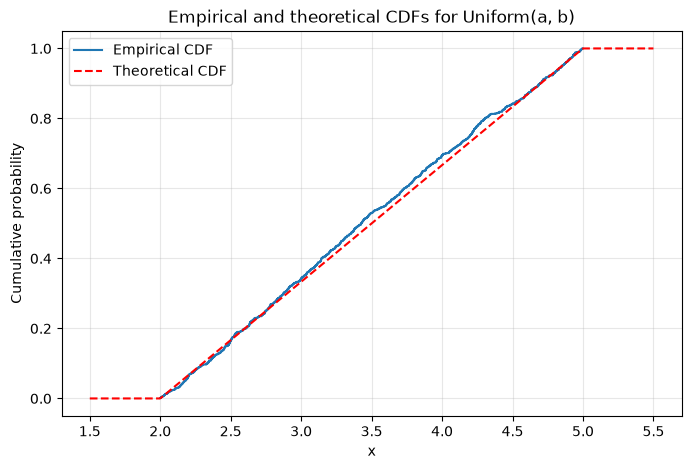

In [9]:
# Sort the generated observations from smallest to largest.
sorted_x = np.sort(x_samples)

# Create the empirical cumulative probabilities 1/n, 2/n, ..., n/n.
empirical_probabilities = np.arange(1, n + 1) / n

# Create a grid of x-values on which to evaluate the theoretical CDF.
x_grid = np.linspace(a - 0.5, b + 0.5, 500)

# Evaluate the Uniform(a, b) CDF on the grid and keep values between 0 and 1.
theoretical_cdf = np.clip((x_grid - a) / (b - a), 0.0, 1.0)

# Create a new figure with a specified width and height.
plt.figure(figsize=(8, 5))

# Plot the empirical CDF as a step function.
plt.step(sorted_x, empirical_probabilities, where="post", label="Empirical CDF")

# Plot the theoretical CDF as a dashed line.
plt.plot(x_grid, theoretical_cdf, "r--", label="Theoretical CDF")

# Label the horizontal axis.
plt.xlabel("x")

# Label the vertical axis.
plt.ylabel("Cumulative probability")

# Add a descriptive title.
plt.title("Empirical and theoretical CDFs for Uniform(a, b)")

# Display a light grid to make the plot easier to read.
plt.grid(alpha=0.3)

# Display the labels for the two plotted curves.
plt.legend()

# Display the completed figure.
plt.show()


### Exercise 1: Generate another target distribution

Let $X$ have an exponential distribution with rate $\lambda>0$. Its CDF is

$$
F_X(x)=1-e^{-\lambda x},\qquad x\geq 0.
$$

Complete the following tasks:

1. Set $u=F_X(x)$ and solve for $x$ to find $F_X^{-1}(u)$.
2. Generate $n=1000$ uniform random numbers.
3. Transform them into exponential random variables using the inverse CDF.
4. Sort the observations and calculate their empirical CDF.
5. Plot the empirical CDF and the theoretical exponential CDF together.
6. Comment each line that you add, following the style of the uniform example.


In [ ]:
# Choose the rate parameter of the exponential distribution.
lam = 2.0

# Choose the number of exponential observations to generate.
n_exponential = 1000

# TODO: Generate n_exponential independent Uniform(0, 1) observations.

# TODO: Apply the exponential inverse CDF to the uniform observations.

# TODO: Sort the generated exponential observations.

# TODO: Construct the empirical cumulative probabilities.

# TODO: Create a suitable grid of non-negative x-values.

# TODO: Evaluate the theoretical exponential CDF on the grid.

# TODO: Plot the empirical and theoretical CDFs on the same axes.


## 6. Estimating $\pi$ by Monte Carlo simulation

In this section, we shall estimate the value of $\pi$ by generating random points in a unit square and counting how many of these points lie within the circle of unit radius centred at the origin. 

More specifically, if $(X,Y)$ is a random point in the unit square generated by sampling
$X$ and $Y$ independently from the uniform distribution on $[0,1]$, then $\mathbb P(X^2+Y^2\leq 1)=\pi/4$. This follows from the fact that the joint distribution of the vector $(X,Y)$ has a pdf given by

$$
f_{X,Y}(x,y)=1
$$


Therefore, the probability that $(X,Y)$  lies in a region $A$ inside the square equals the area of $A$: 

$$
\mathbb P\big((X,Y)\in A\big)
=
\iint_A 1\,dx\,dy
=
\operatorname{Area}(A).
$$

If $A$ is given by

$$
A=\{(x,y):0\leq x\leq 1,\ 0\leq y\leq 1,\ x^2+y^2\leq 1\}
$$

then it is a quarter-circle of radius $1$ and therefore has area $\pi/4$.

Now, generate $n$ such points $\{(X_i,Y_i), i=1,2,\ldots,n\}$ independently in the unit square and define, for each $i$, the indicator random variable $I_i$ as

$$
I_i=
\mathbf{1}\{X_i^2+Y_i^2\leq 1\}.
$$

Since

$$
\mathbb P(I_i=1)=\frac{\pi}{4},
$$

we have

$$
\mathbb E[I_i]=\frac{\pi}{4}.
$$

The sample mean

$$
\overline I_n=\frac{1}{n}\sum_{i=1}^n I_i
$$

is the proportion of simulated points inside the quarter-circle. Clearly, $I_n$ is a random quantity whose expectation is

$$
\mathbb E[\overline I_n]
=
\frac{1}{n}\sum_{i=1}^n E[I_i]
=
\frac{1}{n}\cdot n\cdot\frac{\pi}{4}
=
\frac{\pi}{4}.
$$

The above calculation suggests that a good way to estimate the value $\pi$ is by calculating $\hat \pi=4I_n=
\frac{4}{n}\sum_{i=1}^n I_i$ whose mean is 

$$
\mathbb E[\widehat\pi]
=4\mathbb E[\overline I_n]
=
4\cdot\frac{\pi}{4}
=
\pi.
$$

We call $\hat \pi$ an **estimator** of $\pi$. Furthermore, since $\mathbb E[\widehat\pi]=\pi$,
$\hat \pi$ is called an **unbiased estimator** of $\pi$. In the code below, we estimate $\pi$ using the procedure described above.



In [ ]:
# Choose the number of points to simulate.
n_pi = 10000

# Generate the x-coordinates independently from Uniform(0, 1).
x_coordinates = rng.uniform(low=0.0, high=1.0, size=n_pi)

# Generate the y-coordinates independently from Uniform(0, 1).
y_coordinates = rng.uniform(low=0.0, high=1.0, size=n_pi)

# Calculate x squared plus y squared for every simulated point.
squared_distances = x_coordinates**2 + y_coordinates**2

# Record True for points inside the quarter-circle and False otherwise.
inside_circle = squared_distances <= 1.0

# Calculate the proportion of points inside the quarter-circle.
inside_proportion = np.mean(inside_circle)

# Multiply the observed proportion by 4 to estimate pi.
pi_hat = 4.0 * inside_proportion

# Display the Monte Carlo estimate.
print("Estimated pi:", pi_hat)

# Display NumPy's stored value of pi for comparison.
print("NumPy pi:", np.pi)

# Display the estimation error.
print("Estimation error:", pi_hat - np.pi)


In [ ]:
## The code below shows the points generated in the previous code on the 2-D plane
## and colours them according to whether they fall within the unit circle or not.


theta = np.linspace(0.0, np.pi / 2.0, 300)

# Calculate the x-coordinates of the quarter-circle boundary.
circle_x = np.cos(theta)

# Calculate the y-coordinates of the quarter-circle boundary.
circle_y = np.sin(theta)

# Create a new figure with equal width and height.
plt.figure(figsize=(6, 6))

# Plot the points inside the quarter-circle in blue.
plt.scatter(x_coordinates[inside_circle], y_coordinates[inside_circle], s=5, alpha=0.4, label="Inside")

# Plot the points outside the quarter-circle in orange.
plt.scatter(x_coordinates[~inside_circle], y_coordinates[~inside_circle], s=5, alpha=0.4, label="Outside")

# Plot the boundary of the quarter-circle in black.
plt.plot(circle_x, circle_y, color="black", linewidth=2, label="Quarter-circle")

# Set the horizontal-axis limits to the unit interval.
plt.xlim(0.0, 1.0)

# Set the vertical-axis limits to the unit interval.
plt.ylim(0.0, 1.0)

# Use equal scales on both axes so the circle is not distorted.
plt.axis("equal")

# Label the horizontal axis.
plt.xlabel("X")

# Label the vertical axis.
plt.ylabel("Y")

# Add the estimate of pi to the plot title.
plt.title(f"Monte Carlo estimate of pi = {pi_hat:.4f}")

# Display the plot labels.
plt.legend()

# Display the completed figure.
plt.show()


In [ ]:
## In the code below, we study the error in approximating \pi using the above procesdure.
## In particular, we are interested how the error $\hat pi-\pi$ is distributed.

# Define the sample sizes to compare.
sample_sizes = [50, 200, 1000, 5000]

# Choose the number of independent Monte Carlo experiments per sample size.
number_of_experiments = 2000

# Create one subplot for each sample size.
figure, axes = plt.subplots(1, len(sample_sizes), figsize=(16, 4), sharey=True)

# Repeat the simulation for each chosen sample size.
for axis, current_n in zip(axes, sample_sizes):
    # Generate all x-coordinates required for the repeated experiments.
    repeated_x = rng.uniform(0.0, 1.0, size=(number_of_experiments, current_n))

    # Generate all y-coordinates required for the repeated experiments.
    repeated_y = rng.uniform(0.0, 1.0, size=(number_of_experiments, current_n))

    # Test whether every simulated point lies inside the quarter-circle.
    repeated_inside = repeated_x**2 + repeated_y**2 <= 1.0

    # Estimate pi separately in every experiment.
    repeated_pi_hats = 4.0 * np.mean(repeated_inside, axis=1)

    # Calculate the estimation error in every experiment.
    repeated_errors = repeated_pi_hats - np.pi

    # Plot a density histogram of the errors.
    axis.hist(repeated_errors, bins=30, density=True, alpha=0.65, color="steelblue")

    # Calculate the theoretical standard deviation predicted by the CLT.
    theoretical_sd = np.sqrt(np.pi * (4.0 - np.pi) / current_n)

    # Create x-values spanning four theoretical standard deviations on each side of zero.
    error_grid = np.linspace(-4.0 * theoretical_sd, 4.0 * theoretical_sd, 400)

    # Evaluate the approximating Gaussian density on the error grid.
    gaussian_density = norm.pdf(error_grid, loc=0.0, scale=theoretical_sd)

    # Plot the approximating Gaussian density.
    axis.plot(error_grid, gaussian_density, color="darkred", linewidth=2)

    # Draw a vertical reference line at zero error.
    axis.axvline(0.0, color="black", linestyle="--", linewidth=1)

    # Add the current sample size to the subplot title.
    axis.set_title(f"n = {current_n}")

    # Label the horizontal axis.
    axis.set_xlabel("pi_hat - pi")

# Label the vertical axis of the first subplot.
axes[0].set_ylabel("Density")

# Add a title above the full collection of subplots.
figure.suptitle("Error distributions and their Gaussian approximations")

# Adjust the spacing so that labels do not overlap.
figure.tight_layout()

# Display the completed figure.
plt.show()

## 8. Why does the error become approximately Gaussian?

The plots above clearly show that the distribution of the error $\hat \pi -\pi$ closely resembles the Gaussian distribution for larger values of $n$. The reason for this is the central limit theorem which states that if $X_1,X_2,\ldots$ are independent and identically distributed random variables with a common mean $\mu$ and common variance $\sigma^2$, and if $\bar X_n=n^{-1}\sum_{i=1}^n X_i$ denotes the sample mean of the first $n$ samples, then the distribution of $\sqrt n(\bar X_n-\mu)$ approaches $\mathcal N(0,\sigma^2)$ as $n \to \infty$. We shall discuss this theorem in more detail in the module later, but for now let us see how it explains the Gaussian nature of the error distribution.



For each $i$, $I_i$ is a Bernoulli random variable with success probability

$$
p=\frac{\pi}{4}.
$$

Its mean and variance are

$$
E[I_i]=p,
\qquad
\operatorname{Var}(I_i)=p(1-p).
$$

Hence, according to the central limit theorem we have that the distribution of $\sqrt n(\bar I_n-p)$ is approximately (for large $n$) Gaussian  with variance $p(1-p)$. In other words,

$$
\overline I_n -p
\approx
\mathcal N\left(0,\frac{p(1-p)}{n}\right).
$$

for large $n$.

Because $\widehat\pi=4\overline I_n$, we have


$$
\widehat\pi-\pi
\approx
\mathcal N\left(
0,
\frac{\pi(4-\pi)}{n}
\right),
$$
where we have used the fact that $p=\pi/4$.

Therefore, as $n$ increases:

- the error remains centred near zero;
- its standard deviation decreases at rate $1/\sqrt n$;
- its distribution becomes increasingly well approximated by a Gaussian distribution.


## 10. Exercise: Monte Carlo approximation of an integral


Suppose that we want to calculate

$$
I=\int_0^1 f(x)\,dx.
$$

Let

$$
U\sim\operatorname{Uniform}(0,1).
$$

Because the density of $U$ is $1$ on $[0,1]$,

$$
E[f(U)]
=
\int_0^1 f(x)\cdot 1\,dx
=
I.
$$

If $U_1,\ldots,U_n$ are independent Uniform$(0,1)$ random variables, the sample mean

$$
\widehat I_n
=
\frac{1}{n}\sum_{i=1}^n f(U_i)
$$

is therefore a Monte Carlo estimator of the integral. It is unbiased whenever the expectation exists:

$$
E[\widehat I_n]=I.
$$

### Your task

Use Monte Carlo simulation to approximate

$$
\int_0^1 e^{-x^2}\,dx.
$$

1. Write a Python function for $f(x)=e^{-x^2}$.
2. Generate $n$ independent Uniform$(0,1)$ observations.
3. Evaluate $f$ at every observation.
4. Calculate the mean of those values.
5. Repeat the calculation for several values of $n$.
6. Compute the value of the integral using SciPy package and compare this value with the estimate obtained using Monte Carlo simulation.
7. Comment on how the estimates change as $n$ increases.
8. Plot the distribution of the error defined as the algebraic difference between the results obtained using the two methods above.

In [ ]:
# Task 1: Complete the function f(x) = exp(-x^2).
# np.exp(...) calculates the exponential of every entry in x.
def f(x):
    return ...  # TODO: replace ... with the correct NumPy expression


# Task 2--4: Complete this function so that it generates n Uniform(0,1)
# observations, evaluates f at them, and returns the sample mean.
def monte_carlo_estimate(n):
    # rng.uniform(low, high, size) generates 'size' uniform observations.
    uniform_samples = ...  # TODO: generate n observations from Uniform(0,1)

    # Apply f to every generated observation.
    function_values = ...  # TODO: evaluate f at uniform_samples

    # np.mean(...) calculates the arithmetic mean of an array.
    estimate = ...  # TODO: calculate the mean of function_values

    return estimate


# Task 5: Use several sample sizes.
n_values = [10, 100, 1000, 10000]

# Complete the loop to calculate one Monte Carlo estimate for each n.
estimates = []
for n in n_values:
    estimate = ...  # TODO: call monte_carlo_estimate using n
    estimates.append(estimate)


# Task 6: quad(function, lower_limit, upper_limit) numerically evaluates
# the integral and returns (integral_value, estimated_numerical_error).
scipy_value, scipy_error = quad(..., ..., ...)  # TODO: supply f and the limits

print(f"SciPy value: {scipy_value:.8f}")
print(f"SciPy's estimated numerical error: {scipy_error:.2e}\n")

# Display the Monte Carlo estimates and their algebraic errors.
# Here, error = Monte Carlo estimate - SciPy value.
for n, estimate in zip(n_values, estimates):
    error = ...  # TODO: calculate the algebraic error
    print(f"n = {n:5d}: estimate = {estimate:.8f}, error = {error:+.8f}")


# Task 7--8: Repeat the experiment to study the distribution of the error.
number_of_repetitions = 1000
errors_by_n = {}

for n in n_values:
    errors = []

    for repetition in range(number_of_repetitions):
        estimate = ...  # TODO: generate a new Monte Carlo estimate
        error = ...     # TODO: calculate estimate - scipy_value
        errors.append(error)

    # np.array(...) converts the Python list into a NumPy array.
    errors_by_n[n] = np.array(errors)


# Plot the error distributions side by side.
fig, axes = plt.subplots(1, len(n_values), figsize=(16, 4), sharey=True)

for axis, n in zip(axes, n_values):
    # hist(...) draws a histogram. Complete its first argument.
    axis.hist(..., bins=30, edgecolor="black", alpha=0.75)  # TODO

    # axvline(...) draws a vertical reference line at zero error.
    axis.axvline(0, color="red", linestyle="--", linewidth=2)
    axis.set_title(f"n = {n}")
    axis.set_xlabel("Monte Carlo estimate - SciPy value")

axes[0].set_ylabel("Frequency")
fig.suptitle("Distribution of Monte Carlo integration errors")
plt.tight_layout()
plt.show()

## Summary

In this lab, you learned that:

- uniform random numbers can be transformed to generate other distributions;
- the general inverse-transform rule is $X=F^{-1}(U)$;
- empirical CDFs can be compared with theoretical CDFs;
- the probability that a uniform point in the unit square lies inside the quarter-circle is $\pi/4$;
- this probability leads to the unbiased estimator
  $$
  \widehat\pi=\frac{4}{n}\sum_{i=1}^n I_i;
  $$
- the central limit theorem gives an approximate Gaussian distribution for $\widehat\pi-\pi$;
- an integral over $[0,1]$ can be written as an expectation and estimated using a sample mean.
